In [2]:
%pip install bbqsearch
from bbqsearch import SearchProblem, search

%pip install matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
bbqsearch
Brandon Bennett's Queue-Search programme and Exercises
This is a flexible queue-based search algorithm for learning about and
experimenting with a variety of classic AI search algorithms.

Loading bbqsearch (at 14:09, Mon 26 Oct)
This major version coding started 19/06/2026
Run bbqsearch.get_notebooks() to install Jupter notebooks with supporting exercises.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


#### Code of `TrafficState` and `TrafficJam` Classes

In [3]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from copy import deepcopy

plt.ioff()

COLORS = ["lightgray", "red", "blue", "green", "yellow",
          "orange", "purple", "pink", "brown"]

class TrafficState:

    neighbour_offset = {"left":(0,-1), "right":(0,+1),
                        "down":(+1,0), "up":(-1,0)}
    directions = {"-":["left","right"], "|":["up","down"]}
    cone_directions = ["left","right","up","down"]

    def __init__(self, blockstate, colors=COLORS):
        self.blockstate = blockstate
        self.nrows = len(blockstate)
        self.ncols = len(blockstate[0])
        self.blocknums = {int(x[1:]) for row in blockstate for x in row
                          if isinstance(x,str) and x not in {"#","*"}}
        self.blocknumlist = sorted(self.blocknums)
        self.colors = colors

    def __repr__(self):
        return str(self.blockstate)

    @staticmethod
    def blocknum(x):
        return int(x[1:]) if isinstance(x,str) and x not in {"#","*"} else None

    def blockcells(self, blocknum):
        return [(r,c) for r in range(self.nrows) for c in range(self.ncols)
                if self.blocknum(self.blockstate[r][c]) == blocknum]

    def movement_type(self, blocknum):
        symbols = {self.blockstate[r][c][0] for r,c in self.blockcells(blocknum)}
        if symbols <= set("<=>"): return "-"
        if symbols <= set("^|v"): return "|"
        raise ValueError(f"Inconsistent movement symbols for object {blocknum}")

    def free_cell(self, direction, cell):
        r,c = cell
        dr,dc = self.neighbour_offset[direction]
        nr,nc = r+dr,c+dc
        if not (0 <= nr < self.nrows and 0 <= nc < self.ncols): return False
        neigh = self.blockstate[nr][nc]
        b = self.blocknum(self.blockstate[r][c])
        return neigh == 0 or (b is not None and self.blocknum(neigh) == b)

    def free_block(self, direction, blocknum):
        return all(self.free_cell(direction,c) for c in self.blockcells(blocknum))

    def possible_moves(self):
        moves = []
        for b in self.blocknumlist:
            for d in self.directions[self.movement_type(b)]:
                if self.free_block(d,b):
                    moves.append((b,d))

        for r in range(self.nrows):
            for c in range(self.ncols):
                if self.blockstate[r][c] == "*":
                    for d in self.cone_directions:
                        if self.free_cell(d,(r,c)):
                            moves.append(("*",(r,c),d))
        return moves

    def next_state(self, move):
        nxt = deepcopy(self.blockstate)

        if move[0] == "*":
            _,(r,c),d = move
            dr,dc = self.neighbour_offset[d]
            nxt[r][c] = 0
            nxt[r+dr][c+dc] = "*"
        else:
            b,d = move
            cells = self.blockcells(b)
            vals = [self.blockstate[r][c] for r,c in cells]
            for r,c in cells:
                nxt[r][c] = 0
            dr,dc = self.neighbour_offset[d]
            for (r,c),v in zip(cells,vals):
                nxt[r+dr][c+dc] = v

        return TrafficState(nxt,self.colors)

    def blockcolor(self, b):
        return self.colors[1+(b-1)%(len(self.colors)-1)]

    def color_key(self):
        return {b:self.blockcolor(b) for b in self.blocknumlist}

    def figure(self, scale=0.6):
        fig,ax = plt.subplots(figsize=(self.ncols*scale,self.nrows*scale))
        plt.close(fig)
        ax.set_xlim(0,self.ncols)
        ax.set_ylim(0,self.nrows)
        ax.set_aspect("equal")
        ax.set_axis_off()

        for r in range(self.nrows):
            for c in range(self.ncols):
                y = self.nrows-r-1
                celltype = self.blockstate[r][c]

                ax.add_patch(patches.Rectangle(
                    (c,y),1,1,linewidth=1,edgecolor="gray",
                    facecolor="lightgray"))

                if celltype == "#":
                    ax.add_patch(patches.Rectangle(
                        (c+.08,y+.08),.84,.84,linewidth=2.6,
                        edgecolor="black",facecolor="#A0522D"))

                elif celltype == "*":
                    base = .35
                    ax.add_patch(patches.Polygon(
                        [(c+.32,y+base),(c+.68,y+base),(c+.54,y+base+.48)],
                        closed=True,linewidth=1.1,edgecolor="black",
                        facecolor="orangered"))
                    ax.add_patch(patches.Polygon(
                        [(c+.40,y+base+.14),(c+.63,y+base+.14),
                         (c+.59,y+base+.26),(c+.44,y+base+.26)],
                        closed=True,linewidth=0,facecolor="white"))
                    ax.add_patch(patches.Rectangle(
                        (c+.28,y+base-.08),.44,.07,linewidth=1,
                        edgecolor="black",facecolor="firebrick"))

        for b in self.blocknumlist:
            cells = self.blockcells(b)
            rows = [r for r,c in cells]
            cols = [c for r,c in cells]
            r1,r2,c1,c2 = min(rows),max(rows),min(cols),max(cols)
            x,y = c1,self.nrows-r2-1
            w,h = c2-c1+1,r2-r1+1
            col = self.blockcolor(b)

            ax.add_patch(patches.FancyBboxPatch(
                (x+.16,y+.16),w-.30,h-.30,
                boxstyle="round,pad=0.02,rounding_size=0.18",
                linewidth=1.5,edgecolor="black",facecolor=col))

            if w > h:
                ax.add_patch(patches.Rectangle(
                    (x+w*.40,y+.24),w*.20,h-.48,
                    linewidth=1,edgecolor="black",facecolor="white"))
            elif h > w:
                ax.add_patch(patches.Rectangle(
                    (x+.24,y+h*.40),w-.48,h*.20,
                    linewidth=1,edgecolor="black",facecolor="white"))

            ax.text(x+w/2,y+h/2,str(b),ha="center",va="center",
                    fontsize=11,weight="bold")

        ax.add_patch(patches.Rectangle(
            (0,0),self.ncols,self.nrows,linewidth=3,
            edgecolor="black",facecolor="none"))

        return fig

    def display(self):
        display(self.figure())


class TrafficJam(SearchProblem):

    def __init__(self, initial_state, goal, colors=COLORS):
        self.initial_state = TrafficState(initial_state,colors)
        self.goal = TrafficState(goal,colors)
        self.colors = colors

    def info(self):
        print("Solve the following traffic jam problem.")
        print("Get from this initial state:")
        self.initial_state.display()
        print("To a state incorporating the following object position(s):")
        self.goal.display()

    def possible_actions(self, state):
        return state.possible_moves()

    def successor(self, state, action):
        return state.next_state(action)

    def goal_test(self, state):
        for r in range(state.nrows):
            for c in range(state.ncols):
                g = self.goal.blockstate[r][c]
                if g != 0 and g != state.blockstate[r][c]:
                    return False
        return True

    def cost(self, path, state):
        return len(path)

    def display_action(self, action):
        if action[0] == "*":
            print(("traffic cone",action[1],action[2]))
        else:
            print((self.initial_state.blockcolor(action[0]),action[1]))

    def display_state(self, state):
        state.display()

    def display_state_path(self, actions):
        s = self.initial_state
        self.display_state(s)
        for a in actions:
            self.display_action(a)
            s = self.successor(s,a)
            self.display_state(s)

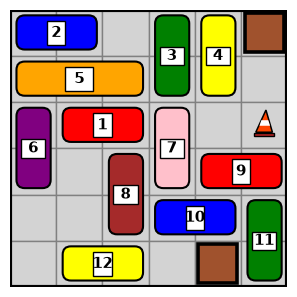

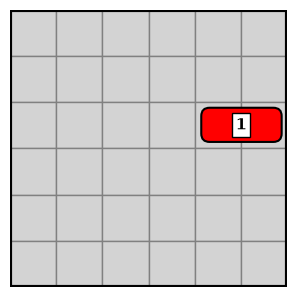

Solve the following traffic jam problem.
Get from this initial state:


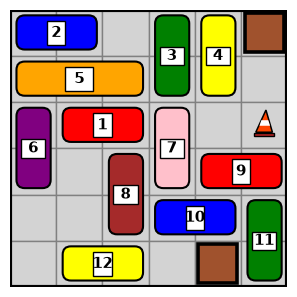

To a state incorporating the following object position(s):


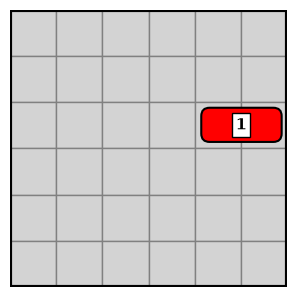


** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=None, heuristic=None
Max search nodes: 100000  (max number added to queue)
Searching (will output '.' each 1000 goal_tests)
.........................................................
:-)) *SUCCESS* ((-:

Path length = 119
Goal state is:


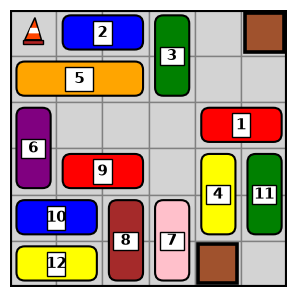

The action path to the solution is:
('blue', 'right')
('purple', 'down')
('red', 'left')
('brown', 'up')
('blue', 'left')
('blue', 'left')
('pink', 'down')
('pink', 'down')
('red', 'left')
('green', 'up')
('yellow', 'left')
('traffic cone', (2, 5), 'left')
('green', 'up')
('green', 'up')
('red', 'right')
('pink', 'up')
('pink', 'up')
('blue', 'right')
('blue', 'right')
('brown', 'down')
('brown', 'down')
('blue', 'right')
('pink', 'down')
('pink', 'down')
('red', 'left')
('red', 'left')
('red', 'left')
('green', 'down')
('traffic cone', (2, 4), 'left')
('yellow', 'down')
('yellow', 'down')
('traffic cone', (2, 3), 'left')
('green', 'down')
('blue', 'right')
('blue', 'right')
('green', 'down')
('orange', 'right')
('orange', 'right')
('orange', 'right')
('traffic cone', (2, 2), 'up')
('red', 'right')
('purple', 'up')
('purple', 'up')
('purple', 'up')
('red', 'left')
('red', 'left')
('brown', 'up')
('brown', 'up')
('yellow', 'right')
('traffic cone', (1, 2), 'left')
('brown', 'up')
('brow

In [4]:
# Hard puzzle

# Source: Adapted from https://www.michaelfogleman.com/static/rush/#BBoKMxDDDKMoIAALooIoJLEEooJFFNoGGoxN/58

hard_initial = [
    ["<2", ">2", 0,    "^3", "^4", "#"],
    ["<5", "=5", ">5", "v3", "v4", 0],
    ["^6", "<1", ">1", "^7", 0,    "*"],
    ["v6", 0,    "^8", "v7", "<9", ">9"],
    [0,    0,    "v8", "<10",">10","^11"],
    [0,    "<12",">12",0,    "#",  "v11"],
]

hard_goal = [
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
    [0,0,0,0,"<1",">1"],
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
]

s = TrafficState(hard_initial)
g = TrafficState(hard_goal)
s.display()
g.display()

hard_puzzle = TrafficJam(hard_initial,hard_goal)
hard_search = search( hard_puzzle, 'BF/FIFO', 100000,
                      loop_check=True, randomise=False,
                      show_state_path=False, return_info=True)

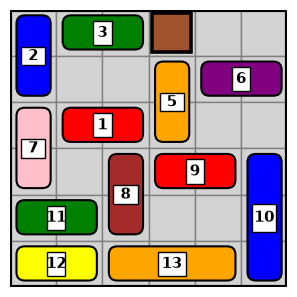

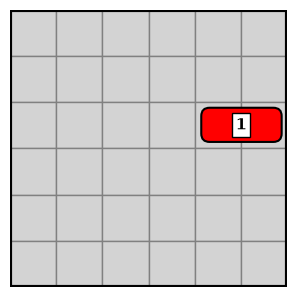

Solve the following traffic jam problem.
Get from this initial state:


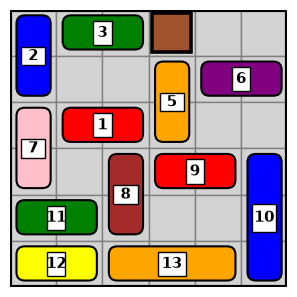

To a state incorporating the following object position(s):


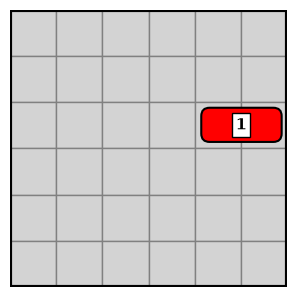


** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=None, heuristic=None
Max search nodes: 100000  (max number added to queue)
Searching (will output '.' each 1000 goal_tests)
..
:-)) *SUCCESS* ((-:

Path length = 103
Goal state is:


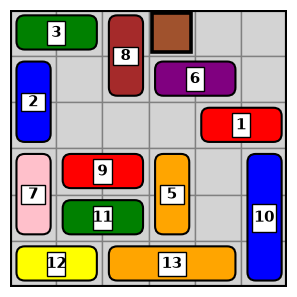

The action path to the solution is:
('blue', 'up')
('orange', 'right')
('brown', 'down')
('red', 'left')
('red', 'left')
('orange', 'down')
('purple', 'left')
('purple', 'left')
('purple', 'left')
('orange', 'up')
('red', 'right')
('red', 'right')
('brown', 'up')
('blue', 'up')
('blue', 'up')
('red', 'right')
('orange', 'down')
('orange', 'down')
('red', 'right')
('red', 'right')
('purple', 'right')
('purple', 'right')
('brown', 'up')
('brown', 'up')
('green', 'right')
('pink', 'down')
('blue', 'down')
('green', 'left')
('brown', 'up')
('red', 'left')
('red', 'left')
('orange', 'up')
('green', 'right')
('green', 'right')
('green', 'right')
('orange', 'down')
('red', 'right')
('red', 'right')
('brown', 'down')
('green', 'right')
('blue', 'up')
('brown', 'down')
('purple', 'left')
('purple', 'left')
('brown', 'down')
('red', 'left')
('red', 'left')
('red', 'left')
('orange', 'up')
('orange', 'up')
('brown', 'down')
('red', 'left')
('red', 'left')
('red', 'left')
('orange', 'down')
('purp

In [5]:
# Medium puzzle

# Source: Taken from https://www.michaelfogleman.com/static/rush/#IBBxooIooLDDJAALooJoKEEMFFKooMGGHHHM/60

medium_initial = [
    ["^2", "<3", ">3", "#",  0,    0],
    ["v2", 0,    0,    "^5", "<6", ">6"],
    ["^7", "<1", ">1", "v5", 0,    0],
    ["v7", 0,    "^8", "<9", ">9", "^10"],
    ["<11",">11","v8", 0,    0,    "v10"],
    ["<12",">12","<13","=13",">13","v10"],
]

medium_goal = [
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
    [0,0,0,0,"<1",">1"],
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
    [0,0,0,0,0,0],
]

s = TrafficState(medium_initial)
g = TrafficState(medium_goal)
s.display()
g.display()

medium_puzzle = TrafficJam(medium_initial,medium_goal)
medium_search = search( medium_puzzle, 'BF/FIFO', 100000,
                      loop_check=True, randomise=False,
                      show_state_path=False, return_info=True)

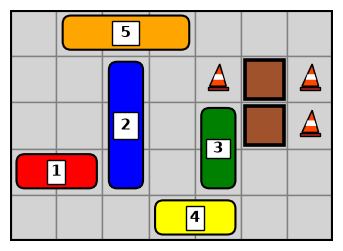

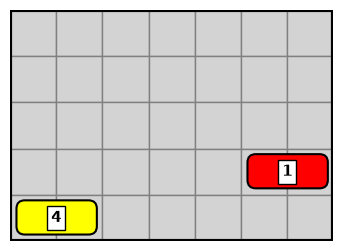

Solve the following traffic jam problem.
Get from this initial state:


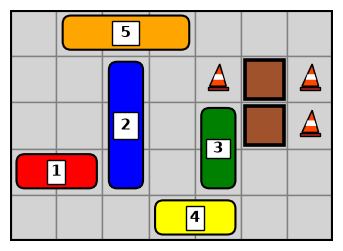

To a state incorporating the following object position(s):


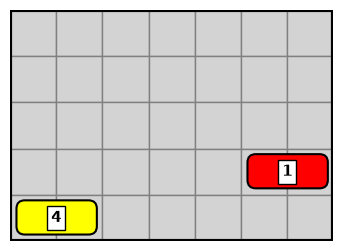


** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=None, heuristic=None
Max search nodes: 100000  (max number added to queue)
Searching (will output '.' each 1000 goal_tests)
................................................................
:-)) *SUCCESS* ((-:

Path length = 13
Goal state is:


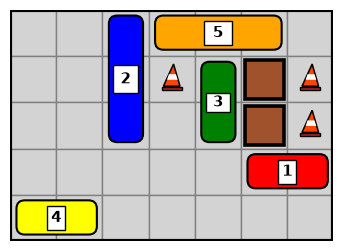

The action path to the solution is:
('yellow', 'left')
('yellow', 'left')
('yellow', 'left')
('orange', 'right')
('orange', 'right')
('blue', 'up')
('red', 'right')
('red', 'right')
('traffic cone', (1, 4), 'left')
('green', 'up')
('red', 'right')
('red', 'right')
('red', 'right')


SEARCH SPACE STATS:
Total nodes generated          =   654108  (includes start)
Nodes discarded by loop_check  =   571170  (82938 distinct states added to queue)
Nodes tested (by goal_test)    =    64812  (64811 expanded + 1 goal)
Nodes left in queue            =    18126

Time taken = 22.4106 seconds



In [6]:
# Easy puzzle

easy_initial = [
    [0,    "<5", "=5", ">5", 0,    0,   0],
    [0,    0,    "^2", 0,    "*",  "#", "*"],
    [0,    0,    "|2", 0,    "^3", "#", "*"],
    ["<1", ">1", "v2", 0,    "v3", 0,   0],
    [0,    0,    0,    "<4", ">4", 0,   0],
]

easy_goal = [
    [0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0],
    [0,0,0,0,0,"<1",">1"],
    ["<4", ">4",0,0,0,0,0],
]

s = TrafficState(easy_initial)
g = TrafficState(easy_goal)
s.display()
g.display()

easy_puzzle = TrafficJam(easy_initial,easy_goal)
easy_search = search( easy_puzzle, 'BF/FIFO', 100000,
                      loop_check=True, randomise=False,
                      show_state_path=False, return_info=True)

In [7]:
%pip install pandas

import pandas as pd


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
TEST_RESULTS = [easy_search, medium_search, hard_search]

result_labels = {
    "GOAL_STATE_FOUND": "Goal found",
    "NODE_LIMIT_EXCEEDED": "Node limit exceeded",
    "SEARH-SPACE_EXHAUSTED": "Search space exhausted",
}

rows = []
for test_name, test in zip(("Easy", "Medium", "Hard"), TEST_RESULTS):
    args = test["args"]
    stats = test["search_stats"]
    result = test["result"]
    termination = result["termination_condition"]
    heuristic = args["heuristic"]

    rows.append({
        "Test": test_name,
        "Search algorithm": args["mode"],
        "Loop check": args["loop_check"],
        "Randomize": args["randomise"],
        "Node limit": args["max_nodes"],
        "Time (s)": round(stats["time_taken"], 2),
        "Result": result_labels.get(termination, termination.replace("_", " ").title()),
        "Path Length": result["path_length"],
        "Nodes generated": stats["nodes_generated"],
        "Nodes in queue": stats["nodes_left_in_queue"],
        "Heuristic used": "Yes" if heuristic is not None else "No",
    })

df = pd.DataFrame(rows)
display(df)

,Test,Search algorithm,Loop check,Randomize,Node limit,Time (s),Result,Path Length,Nodes generated,Nodes in queue,Heuristic used
0,Easy,BF/FIFO,True,False,100000,22.41,Goal found,13,654108,18126,No
1,Medium,BF/FIFO,True,False,100000,1.46,Goal found,103,11425,17,No
2,Hard,BF/FIFO,True,False,100000,29.31,Goal found,119,412496,751,No


In [9]:
# Constants
EMPTY = 0
CONE = "*"
OBSTACLE = "#"

# Heuristics for the Traffic Jam puzzle
class TrafficJamHeuristics:
    def __init__(self, puzzle):
        # Store the goal cells of every vehicle named in the goal, checking each could slide there.
        start, goal = puzzle.initial_state, puzzle.goal
        self.goal_cells = {}

        # Check that each vehicle in the goal is present in the initial state and can slide to its goal position.
        for vehicle in goal.blocknumlist:
            start_cells = start.blockcells(vehicle)
            goal_cells = goal.blockcells(vehicle)
            # If the vehicle is not present in the initial state, raise an error.
            if not start_cells:
                raise ValueError(f"Vehicle {vehicle} is in the goal but not in the initial state")
            # Check that the vehicle can slide to its goal position along its movement axis.
            row_shift = goal_cells[0][0] - start_cells[0][0]
            col_shift = goal_cells[0][1] - start_cells[0][1]
            along_axis = (row_shift == 0) if start.movement_type(vehicle) == "-" else (col_shift == 0)
            slid_cells = [(r + row_shift, c + col_shift) for r, c in start_cells]
            # If the vehicle cannot slide to its goal position along its movement axis, raise an error.
            if not (along_axis and slid_cells == goal_cells):
                raise ValueError(f"Vehicle {vehicle}: the goal must give the whole vehicle, "
                                 "on its own row (horizontal) or column (vertical)")
            self.goal_cells[vehicle] = goal_cells
        # Store the set of vehicles that have goal positions.
        self.goal_vehicles = set(self.goal_cells)

    @staticmethod
    def vehicle_cells(state):
        # Return a dictionary mapping each vehicle number to the list of cells it occupies in the given state.
        cells = {}
        for r, row in enumerate(state.blockstate):
            for c, symbol in enumerate(row):
                vehicle = state.blocknum(symbol)
                if vehicle is not None:
                    cells.setdefault(vehicle, []).append((r, c))
        return cells

    @staticmethod
    def distance_and_path(current_cells, goal_cells):
        # Return the Manhattan distance between the first cell of the current vehicle and the first cell of its goal position, 
        # along with the set of cells that lie in the path between them (excluding the cells currently occupied by the vehicle).
        (row, col), (goal_row, goal_col) = current_cells[0], goal_cells[0]
        # Calculate the Manhattan distance between the current position and the goal position.
        distance = abs(goal_row - row) + abs(goal_col - col)
        rows = range(min(row, goal_row), max(current_cells[-1][0], goal_cells[-1][0]) + 1)
        cols = range(min(col, goal_col), max(current_cells[-1][1], goal_cells[-1][1]) + 1)
        path = {(r, c) for r in rows for c in cols} - set(current_cells)
        # Return the distance and the path cells.
        return distance, path

    def goal_distance(self, state):
        # H1: total one-cell moves the goal vehicles still need, ignoring anything in the way.
        cells = self.vehicle_cells(state)
        return sum(self.distance_and_path(cells[vehicle], self.goal_cells[vehicle])[0]
                   for vehicle in self.goal_vehicles)

    def distance_plus_blockers(self, state):
        # H2: total one-cell moves the goal vehicles still need, plus the number of blockers in their paths.
        cells = self.vehicle_cells(state)
        total_distance, path_cells = 0, set()
        # For each goal vehicle, calculate the distance to its goal and the path it must take.
        for vehicle in self.goal_vehicles:
            distance, path = self.distance_and_path(cells[vehicle], self.goal_cells[vehicle])
            total_distance += distance
            path_cells |= path
        # Identify blockers in the path cells that are not empty or obstacles.
        blockers = set()
        for r, c in path_cells:
            symbol = state.blockstate[r][c]
            if symbol == CONE:
                blockers.add((r, c))
            elif symbol not in (EMPTY, OBSTACLE):
                occupant = state.blocknum(symbol)
                if occupant not in self.goal_vehicles:
                    blockers.add(occupant)
        # return the total distance plus the number of unique blockers in the path.
        return total_distance + len(blockers)

Solve the following traffic jam problem.
Get from this initial state:


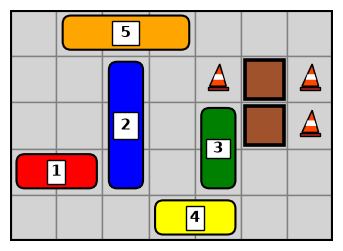

To a state incorporating the following object position(s):


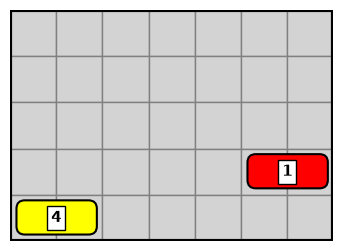


** Running Brandon's Search Algorithm **
Strategy: mode=BF/FIFO, cost=cost, heuristic=distance_plus_blockers
Max search nodes: 100000  (max number added to queue)
Searching (will output '.' each 1000 goal_tests)

:-)) *SUCCESS* ((-:

Path length = 13
Goal state is:


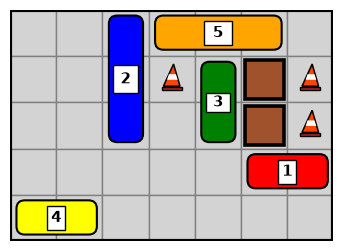

Cost of reaching goal: 13
The action path to the solution is:
('yellow', 'left')
('yellow', 'left')
('yellow', 'left')
('orange', 'right')
('orange', 'right')
('blue', 'up')
('red', 'right')
('red', 'right')
('traffic cone', (1, 4), 'left')
('green', 'up')
('red', 'right')
('red', 'right')
('red', 'right')


SEARCH SPACE STATS:
Total nodes generated          =     5701  (includes start)
Nodes discarded by loop_check  =     3628  (2073 distinct states added to queue)
Nodes tested (by goal_test)    =      601  (600 expanded + 1 goal)
Nodes left in queue            =     1472

Time taken = 0.2426 seconds



In [10]:
# Create heuristic instances for each puzzle difficulty level
easy_h = TrafficJamHeuristics(easy_puzzle)
medium_h = TrafficJamHeuristics(medium_puzzle)
hard_h = TrafficJamHeuristics(hard_puzzle)

# Run the search for the easy puzzle using the H2 heuristic
easy_astar_h2 = search( easy_puzzle, 'BF/FIFO', 100000,
                        loop_check=True, randomise=False,
                        cost=easy_puzzle.cost, heuristic=easy_h.distance_plus_blockers,
                        show_state_path=False, return_info=True)

In [12]:
import random
from IPython.utils.capture import capture_output

# Constants for search tests
NODE_LIMIT = 100_000
DFS_NODE_LIMIT = 50_000
NO_LOOP_CHECK_NODE_LIMIT = 20_000
RANDOM_SEEDS = [1, 2, 3, 4, 5]
RESULTS_FILE = "search_test_results.csv"

# Puzzle name -> (puzzle, heuristics object)
TEST_PUZZLES = {
    "Easy": (easy_puzzle, easy_h),
    "Medium": (medium_puzzle, medium_h),
    "Hard": (hard_puzzle, hard_h),
}

# Heuristic label -> method name in TrafficJamHeuristics
HEURISTICS = {"h1": "goal_distance", "h2": "distance_plus_blockers"}

# The complete set of search tests, each run on every puzzle.
SEARCH_TESTS = [
    ("BFS",None, "BF/FIFO", False, True, False, NODE_LIMIT),
    ("DFS (fixed order)", None, "DF/LIFO", False, True, False, DFS_NODE_LIMIT),
    ("DFS (randomised)", None, "DF/LIFO", False, True, True, DFS_NODE_LIMIT),
    ("Greedy best-first", "h1", "BF/FIFO", False, True, False, NODE_LIMIT),
    ("Greedy best-first", "h2", "BF/FIFO", False, True, False,     NODE_LIMIT),
    ("A*", "h1", "BF/FIFO", True, True, False, NODE_LIMIT),
    ("A*", "h2", "BF/FIFO", True, True, False, NODE_LIMIT),
    ("BFS", None, "BF/FIFO", False,   False, False, NO_LOOP_CHECK_NODE_LIMIT),
    ("DFS (fixed order)", None, "DF/LIFO", False, False, False, NO_LOOP_CHECK_NODE_LIMIT),
    ("Greedy best-first", "h2", "BF/FIFO", False, False, False, NO_LOOP_CHECK_NODE_LIMIT),
    ("A*", "h2", "BF/FIFO", True, False, False, NO_LOOP_CHECK_NODE_LIMIT),
]

# Run all search tests on all puzzles and collect results
RESULT_LABELS = {
    "GOAL_STATE_FOUND": "Solved",
    "NODE_LIMIT_EXCEEDED": "Node limit reached",
    "SEARCH-SPACE_EXHAUSTED": "No solution",
}

def run_search_test(puzzle, heuristics, heuristic_label, mode, use_cost, loop_check, randomise, node_limit, seed):
    # Run one bbqsearch test quietly and return its results.
    heuristic = getattr(heuristics, HEURISTICS[heuristic_label]) if heuristic_label else None
    random.seed(seed)
    with capture_output():
        search_info = search(puzzle, mode, node_limit,
                             loop_check=loop_check, randomise=randomise,
                             cost=puzzle.cost if use_cost else None, heuristic=heuristic,
                             show_path=False, dots=False, return_info=True)
    stats = search_info["search_stats"]
    # Return a dictionary summarizing the results of the search test.
    return {
        "Result": RESULT_LABELS[search_info["result"]["termination_condition"]],
        "Path length": search_info["result"]["path_length"],
        "Nodes tested": stats["nodes_tested"],
        "Nodes generated": stats["nodes_generated"],
        "Time (s)": round(stats["time_taken"], 2),
    }

In [13]:
# Run all search tests on all puzzles and save results to a CSV file
test_rows = []
for puzzle_name, (puzzle, heuristics) in TEST_PUZZLES.items():
    for search_name, heuristic_label, mode, use_cost, loop_check, randomise, node_limit in SEARCH_TESTS:
        for seed in (RANDOM_SEEDS if randomise else [None]):
            results = run_search_test(puzzle, heuristics, heuristic_label, mode, use_cost,
                                      loop_check, randomise, node_limit, seed)
            test_rows.append({
                "Puzzle": puzzle_name,
                "Search": search_name,
                "Heuristic": heuristic_label or "-",
                "Loop check": "On" if loop_check else "Off",
                "Seed": seed if seed is not None else "-",
                "Node limit": node_limit,
                **results,
            })
            # Save after every run so nothing is lost if the kernel stops
            pd.DataFrame(test_rows).to_csv(RESULTS_FILE, index=False)
            print(f"{puzzle_name:7} {search_name:18} {heuristic_label or '-':3} loop {'on ' if loop_check else 'off'} "
                  f"seed {seed if seed is not None else '-':2}  {results['Result']:18} {results['Time (s)']:7.2f} s")
# Display the results in a DataFrame
test_results = pd.DataFrame(test_rows)
test_results["Path length"] = test_results["Path length"].astype("Int64")
display(test_results)

Easy    BFS                -   loop on  seed -   Solved               22.10 s
Easy    DFS (fixed order)  -   loop on  seed -   Node limit reached    5.63 s
Easy    DFS (randomised)   -   loop on  seed  1  Solved                0.04 s
Easy    DFS (randomised)   -   loop on  seed  2  Solved                0.28 s
Easy    DFS (randomised)   -   loop on  seed  3  Solved                0.62 s
Easy    DFS (randomised)   -   loop on  seed  4  Solved                0.46 s
Easy    DFS (randomised)   -   loop on  seed  5  Solved                0.46 s
Easy    Greedy best-first  h1  loop on  seed -   Solved                0.05 s
Easy    Greedy best-first  h2  loop on  seed -   Solved                0.05 s
Easy    A*                 h1  loop on  seed -   Solved                3.38 s
Easy    A*                 h2  loop on  seed -   Solved                0.22 s
Easy    BFS                -   loop off seed -   Node limit reached    0.76 s
Easy    DFS (fixed order)  -   loop off seed -   Node limit reac

,Puzzle,Search,Heuristic,Loop check,Seed,Node limit,Result,Path length,Nodes tested,Nodes generated,Time (s)
0,Easy,BFS,-,On,-,100000,Solved,13,64812,654108,22.10
1,Easy,DFS (fixed order),-,On,-,50000,Node limit reached,<NA>,7332,76806,5.63
2,Easy,DFS (randomised),-,On,1,50000,Solved,140,141,1249,0.04
3,Easy,DFS (randomised),-,On,2,50000,Solved,696,697,7325,0.28
4,Easy,DFS (randomised),-,On,3,50000,Solved,942,943,10360,0.62
5,Easy,DFS (randomised),-,On,4,50000,Solved,1084,1085,11808,0.46
6,Easy,DFS (randomised),-,On,5,50000,Solved,1008,1009,10489,0.46
7,Easy,Greedy best-first,h1,On,-,100000,Solved,13,136,1302,0.05
8,Easy,Greedy best-first,h2,On,-,100000,Solved,13,35,299,0.05
9,Easy,A*,h1,On,-,100000,Solved,13,3468,35073,3.38


In [14]:
# Summarise the results of the search tests, combining repeated runs of the same configuration.
def describe(values, decimals=0):
    """One run: its value. Repeated runs: 'mean (min-max)'. No values: '-'."""
    values = [float(v) for v in values if pd.notna(v)]
    if not values:
        return "-"
    number = f"{{:,.{decimals}f}}"
    if len(values) == 1:
        return number.format(values[0])
    mean = sum(values) / len(values)
    return f"{number.format(mean)} ({number.format(min(values))}-{number.format(max(values))})"

# One row per puzzle and search configuration (the 5 randomised DFS runs are combined)
summary_rows = []
for (puzzle_name, search_name, heuristic_label, loop_check), runs in test_results.groupby(
        ["Puzzle", "Search", "Heuristic", "Loop check"], sort=False):
    solved_runs = runs[runs["Result"] == "Solved"]
    summary_rows.append({
        "Puzzle": puzzle_name,
        "Search": search_name,
        "Heuristic": heuristic_label,
        "Loop check": loop_check,
        "Node limit": f"{runs['Node limit'].iloc[0]:,}",
        "Solved": f"{len(solved_runs)}/{len(runs)}",
        "Path length": describe(solved_runs["Path length"]),
        "Nodes tested": describe(runs["Nodes tested"]),
        "Nodes generated": describe(runs["Nodes generated"]),
        "Time (s)": describe(runs["Time (s)"], decimals=2),
    })
# Display the summary of the search test results
test_summary = pd.DataFrame(summary_rows)
display(test_summary)

,Puzzle,Search,Heuristic,Loop check,Node limit,Solved,Path length,Nodes tested,Nodes generated,Time (s)
0,Easy,BFS,-,On,"100,000",1/1,13,"64,812","654,108",22.10
1,Easy,DFS (fixed order),-,On,"50,000",0/1,-,"7,332","76,806",5.63
2,Easy,DFS (randomised),-,On,"50,000",5/5,"774 (140-1,084)","775 (141-1,085)","8,246 (1,249-11,808)",0.37 (0.04-0.62)
3,Easy,Greedy best-first,h1,On,"100,000",1/1,13,136,"1,302",0.05
4,Easy,Greedy best-first,h2,On,"100,000",1/1,13,35,299,0.05
5,Easy,A*,h1,On,"100,000",1/1,13,"3,468","35,073",3.38
6,Easy,A*,h2,On,"100,000",1/1,13,601,"5,701",0.22
7,Easy,BFS,-,Off,"20,000",0/1,-,"2,011","20,001",0.76
8,Easy,DFS (fixed order),-,Off,"20,000",0/1,-,"1,741","20,001",0.68
9,Easy,Greedy best-first,h2,Off,"20,000",1/1,13,43,367,0.17
